# Import packages

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import os
import torch
from torch.utils.data import Dataset, DataLoader
import rasterio
import numpy as np
import glob

import matplotlib.pyplot as plt

In [4]:
#from google.colab import drive
#drive.mount('/content/drive/')

#########################
## 0. Inlezen Tif files
#########################

In [2]:
class TiffDataset(Dataset):
    def __init__(self, file_paths, target_size=(512, 512)):
        """
        file_paths: lijst van volledige paden naar de .tif bestanden
        target_size: De gewenste uitvoerhoogte en -breedte voor alle beelden (H, W)
        """
        self.file_paths = file_paths
        self.target_size = target_size

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        file_path = self.file_paths[idx]
        with rasterio.open(file_path) as src:
            data = src.read().astype(np.float32)

        # Check if padding is needed
        current_channels, current_height, current_width = data.shape
        pad_h = self.target_size[0] - current_height
        pad_w = self.target_size[1] - current_width

        if pad_h < 0 or pad_w < 0:
            # If image is larger than target_size, resize or crop.
            # For simplicity, we'll raise an error here.
            # For production, consider resizing/cropping strategies.
            raise ValueError(f"Image {file_path} (shape {data.shape}) is larger than target_size {self.target_size}. Currently only padding smaller images is supported.")

        if pad_h > 0 or pad_w > 0:
            # Pad with zeros. (channels, height, width)
            data = np.pad(data, ((0, 0), (0, pad_h), (0, pad_w)), mode='constant', constant_values=0)

        mask = ~np.isnan(data)  # True where data is valid (after potential padding)
        data = np.nan_to_num(data, nan=0.0)  # Fill NaNs with 0 to prevent PyTorch errors

        x = torch.from_numpy(data)
        mask = torch.from_numpy(mask.astype(np.float32))

        return x, mask

In [6]:
# class CachedTiffDataset(Dataset):
#     def __init__(self, file_paths, target_size=(512, 512)):
#         self.data_list = []
#         self.mask_list = []
        
#         print("Preloading dataset into memory...")
#         for file_path in file_paths:
#             with rasterio.open(file_path) as src:
#                 data = src.read().astype(np.float32)

#             current_channels, current_height, current_width = data.shape
#             pad_h = target_size[0] - current_height
#             pad_w = target_size[1] - current_width

#             if pad_h > 0 or pad_w > 0:
#                 data = np.pad(data, ((0, 0), (0, pad_h), (0, pad_w)), mode='constant', constant_values=0)

#             mask = ~np.isnan(data)
#             data = np.nan_to_num(data, nan=0.0)

#             self.data_list.append(torch.from_numpy(data))
#             self.mask_list.append(torch.from_numpy(mask.astype(np.float32)))

#     def __len__(self):
#         return len(self.data_list)

#     def __getitem__(self, idx):
#         return self.data_list[idx], self.mask_list[idx]

In [7]:
# class FastTensorDataset(Dataset):

#   def __init__(self, pt_folder_path):
#     self.file_paths = glob.glob(os.path.join(pt_folder_path, "*.pt"))

#   def __len__(self):
#     return len(self.file_paths)

#   def __getitem__(self, idx):
#     data = torch.load(self.file_paths[idx], weights_only=True)
#     return data["x"], data["mask"]

In [3]:
class FastNpzDataset(Dataset):

  def __init__(self, npz_folder_path):
    self.file_paths = glob.glob(os.path.join(npz_folder_path, "*.npz"))

  def __len__(self):
    return len(self.file_paths)

  def __getitem__(self, idx):
    # Load using np.load
    with np.load(self.file_paths[idx]) as loaded:
      x = torch.from_numpy(loaded["x"].copy())
      mask = torch.from_numpy(loaded["mask"].copy())
    return x, mask

# ==========================================
## 1. Conv-VAE Architecture Definition
# ==========================================

In [4]:
class ConvVAE512(nn.Module):
    def __init__(self, in_channels=35, latent_dim=128):
        super(ConvVAE512, self).__init__()
        self.latent_dim = latent_dim

        # --- Encoder ---
        # Input: (B, in_channels, 512, 512)
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=4, stride=2, padding=1),  # -> (B, 32, 256, 256)
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),           # -> (B, 64, 128, 128)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),          # -> (B, 128, 64, 64)
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),         # -> (B, 256, 32, 32)
            nn.BatchNorm2d(256),
            nn.ReLU(),
            # Additional layers for 512x512 resolution
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1),         # -> (B, 512, 16, 16)
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=4, stride=2, padding=1),         # -> (B, 512, 8, 8)
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.Flatten()                                                     # -> (B, 512 * 8 * 8 = 32768)
        )

        # Bottleneck
        self.fc_mu = nn.Linear(512 * 8 * 8, latent_dim)
        self.fc_logvar = nn.Linear(512 * 8 * 8, latent_dim)

        # --- Decoder ---
        self.decoder_input = nn.Linear(latent_dim, 512 * 8 * 8)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512, 512, kernel_size=4, stride=2, padding=1), # -> (B, 512, 16, 16)
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1), # -> (B, 256, 32, 32)
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1), # -> (B, 128, 64, 64)
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # -> (B, 64, 128, 128)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),   # -> (B, 32, 256, 256)
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, in_channels, kernel_size=4, stride=2, padding=1), # -> (B, in_channels, 512, 512)
            #nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)  # Prevents explosion
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.decoder_input(z)
        h = h.view(-1, 512, 8, 8)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar

# ==========================================
## 2. VAE Loss Function
# ==========================================

In [5]:
import torch.nn.functional as F

# def vae_loss_function(recon_x, x, mask, mu, logvar, beta=1.0):
#     batch_size = x.size(0)

#     binary_indices = list(range(7, 15))
#     continuous_indices = [i for i in range(x.size(1)) if i not in binary_indices]

#     # Calculate unreduced element-wise loss
#     mse = F.mse_loss(recon_x[:, continuous_indices], x[:, continuous_indices], reduction='none')
#     bce = F.binary_cross_entropy(recon_x[:, binary_indices], x[:, binary_indices], reduction='none')

#     # Mask out invalid pixels
#     masked_mse = (mse * mask[:, continuous_indices]).sum()
#     masked_bce = (bce * mask[:, binary_indices]).sum()

#     recon_loss = (masked_mse + masked_bce) / batch_size
#     kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size

#     return recon_loss + beta * kl_loss, recon_loss, kl_loss


def vae_loss_function(recon_logits, x, mask, mu, logvar, beta=1.0):
  binary_indices = list(range(2, 6))
  continuous_indices = [i for i in range(x.size(1)) if i not in binary_indices]

  # 1. Continuous channels: apply sigmoid to logits to bring predictions to [0, 1]
  recon_cont = torch.sigmoid(recon_logits[:, continuous_indices])
  x_cont = x[:, continuous_indices]
  mse = F.mse_loss(recon_cont, x_cont, reduction="none")

  # 2. Binary channels: use raw logits directly with BCEWithLogits
  x_binary = torch.clamp(x[:, binary_indices], 0.0, 1.0)
  bce = F.binary_cross_entropy_with_logits(
      recon_logits[:, binary_indices], x_binary, reduction="none"
  )

  # Masked losses
  mask_cont = mask[:, continuous_indices]
  mask_bin = mask[:, binary_indices]

  masked_mse = (mse * mask_cont).sum() / (mask_cont.sum() + 1e-8)
  masked_bce = (bce * mask_bin).sum() / (mask_bin.sum() + 1e-8)

  recon_loss = masked_mse + masked_bce

  # KL Loss (sum over latent dimensions, mean over batch)
  kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)
  kl_loss = kl_loss.mean()

  total_loss = recon_loss + beta * kl_loss
  return total_loss, recon_loss, kl_loss

# ==========================================
## 3. Training Loop Example
# ==========================================

In [6]:
def train_vae_with_tiffs(tif_folder_path, save_path="best_vae_model.pt", patience=10):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # 1. Hyperparameters
    IN_CHANNELS = 35
    LATENT_DIM = 128
    BATCH_SIZE = 16
    EPOCHS = 500  # Increased max epochs since early stopping will halt training when needed
    LEARNING_RATE = 1e-3

    # 2. Dataset & DataLoader
    dataset = FastNpzDataset(tif_folder_path)
    dataloader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )
    print("dataloader is ready")

    # 3. Initialize Model and Optimizer
    model = ConvVAE512(in_channels=IN_CHANNELS, latent_dim=LATENT_DIM).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    epoch_losses = []
    epoch_recon_losses = []
    epoch_kl_losses = []

    # --- Early Stopping & Checkpointing Variables ---
    best_loss = float('inf')
    patience_counter = 0

    # 4. Training Loop
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, total_recon, total_kl = 0, 0, 0
        
        for batch_idx, (x, mask) in enumerate(dataloader):
            x = x.to(device)
            mask = mask.to(device)

            optimizer.zero_grad()
            recon_x, mu, logvar = model(x)
            
            loss, recon_l, kl_l = vae_loss_function(recon_x, x, mask, mu, logvar, beta=1.0)
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_loss += loss.item()
            total_recon += recon_l.item()
            total_kl += kl_l.item()

        num_batches = len(dataloader)
        avg_loss = total_loss / num_batches
        avg_recon = total_recon / num_batches
        avg_kl = total_kl / num_batches

        epoch_losses.append(avg_loss)
        epoch_recon_losses.append(avg_recon)
        epoch_kl_losses.append(avg_kl)

        print(f"Epoch [{epoch}/{EPOCHS}] - Loss: {avg_loss:.2f} | "
              f"Recon MSE/BCE: {avg_recon:.2f} | KL Div: {avg_kl:.2f}")

        # --- Save Optimal Model State & Early Stopping Logic ---
        if avg_loss < best_loss:
            best_loss = avg_loss
            patience_counter = 0
            torch.save(model.state_dict(), save_path)
            print(f"  --> Optimal loss improved to {best_loss:.2f}. Saved model state to '{save_path}'.")
        else:
            patience_counter += 1
            print(f"  --> Loss did not improve. Early stopping counter: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print(f"/n[Early Stopping Triggered] Optimal loss hasn't improved for {patience} consecutive epochs.")
            break

    # 5. Load the best weights back into the model before returning
    if os.path.exists(save_path):
        print(f"/nLoading best model weights from '{save_path}' with optimal loss: {best_loss:.2f}")
        model.load_state_dict(torch.load(save_path, weights_only=True))

    history = {
        "loss": epoch_losses,
        "reconstruction_loss": epoch_recon_losses,
        "kl_loss": epoch_kl_losses
    }

    return model, device, history

In [12]:
import os
import glob

#file_paths = glob.glob("G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_covariabelen/blocks/covariates_VAE_dataset/*.tif")
file_paths = glob.glob("C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz/*.npz")
print(f"Found {len(file_paths)} TIFF files")
print(file_paths[:5])

Found 976 TIFF files
['C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz\\Covariates_vae_tile_id_1000.npz', 'C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz\\Covariates_vae_tile_id_1001.npz', 'C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz\\Covariates_vae_tile_id_1002.npz', 'C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz\\Covariates_vae_tile_id_1006.npz', 'C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz\\Covariates_vae_tile_id_1018.npz']


In [13]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [14]:
SAVE_MODEL_PATH = "G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_VAE_state_dict.pt"

model, device, history = train_vae_with_tiffs(
    tif_folder_path="C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz",
    save_path=SAVE_MODEL_PATH,
    patience=10
)

Using device: cuda
dataloader is ready


KeyboardInterrupt: 

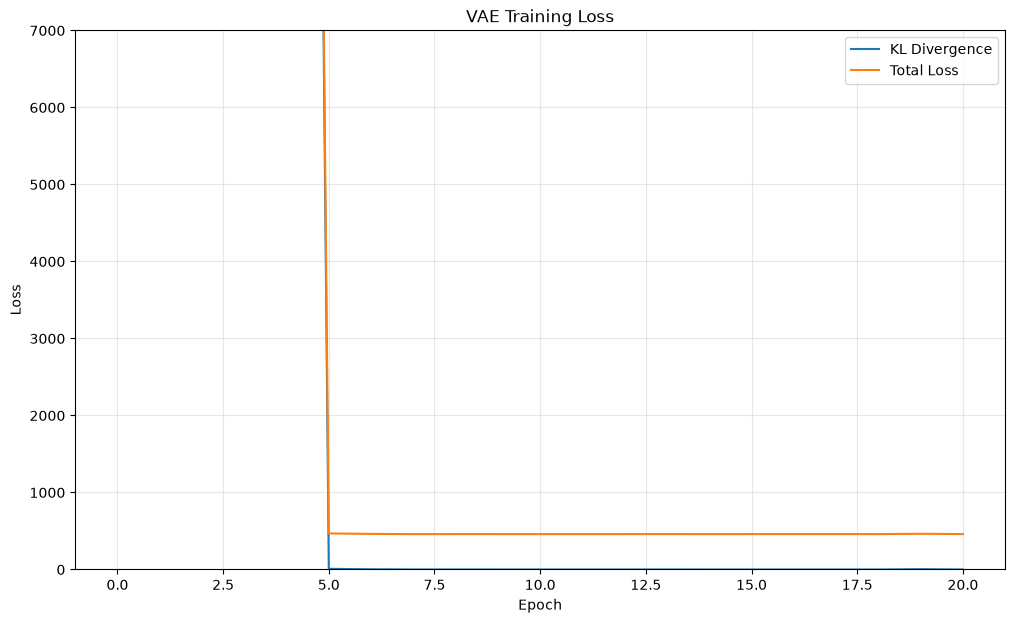

In [ ]:
plt.figure(figsize=(12, 7))
plt.plot(history["kl_loss"], label="KL Divergence")
plt.plot(history["loss"], label="Total Loss")
ax = plt.gca()
#ax.set_xlim([xmin, xmax])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

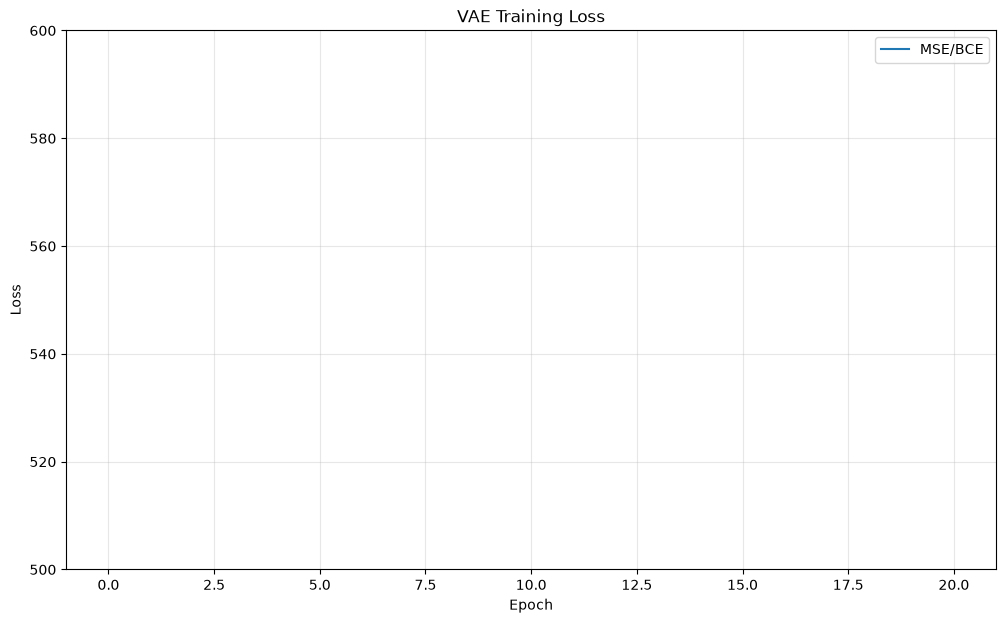

In [ ]:
plt.figure(figsize=(12, 7))
plt.plot(history["reconstruction_loss"], label="MSE/BCE")
ax = plt.gca()
#ax.set_xlim([xmin, xmax])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print(history)
type(history)

{'loss': [2255283172521.9136, 1115713770.713373, 3992033578366.256, 61349643.09940426, 56580.44211465804, 468.6001877081199, 462.07034401815446, 459.6106407290599, 459.95636236472205, 459.91101774622183, 459.5214818735592, 459.5965841324603, 459.903323314229, 460.10377977715166, 459.7167173291816, 459.95927454213626, 460.2220694119813, 460.1769474217149, 459.83820780769724, 463.8143690765881, 459.95244760982325], 'reconstruction_loss': [464.13145621878203, 462.2949849113089, 461.11928220655096, 460.3368785420402, 460.09462100169696, 459.73486278096186, 459.4466252561475, 459.336157626793, 459.7855339675653, 459.77151439229, 459.49389698466314, 459.56828032946976, 459.8828545242059, 459.63048866146903, 459.7164926997951, 459.95190779889214, 460.1887046939037, 460.1769119012551, 459.8350584936924, 459.6000141081263, 459.9479565229572], 'kl_loss': [2255283172073.7964, 1115713315.6443152, 3992033577934.899, 61349182.03512774, 56120.34822081738, 8.865326156839728, 2.62371826898612, 0.274483

dict

In [15]:
import csv

with open("G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/history_VAE.csv", "w", newline="") as f:
    w = csv.DictWriter(f, history.keys())
    w.writeheader()
    w.writerow(history)

NameError: name 'history' is not defined

In [ ]:
# # Inspect raw statistics of your loaded dataset
# temp_dataset = FastNpzDataset("C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz")
# sample_x, sample_mask = temp_dataset[0]  # Get first sample

# print(f"Sample tensor shape: {sample_x.shape}/n")
# print(f"{'Band':<6} | {'Min':<10} | {'Max':<10} | {'Mean':<10} | {'Std':<10}")
# print("-" * 55)

# for i in range(sample_x.shape[0]):
#     band_data = sample_x[i][sample_mask[i] == 1]  # Only consider valid pixels
#     if len(band_data) > 0:
#         b_min = band_data.min().item()
#         b_max = band_data.max().item()
#         b_mean = band_data.mean().item()
#         b_std = band_data.std().item()
#         print(f"{i:<6} | {b_min:<10.2f} | {b_max:<10.2f} | {b_mean:<10.2f} | {b_std:<10.2f}")
#     else:
#         print(f"{i:<6} | No valid masked data")
    

In [ ]:
# PATH = "G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/VAE_state_dict.pt"
# torch.save(model.state_dict(), PATH)

In [7]:
PATH = "G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/VAE_state_dict.pt"
PATH2 = "G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_VAE_state_dict.pt"
model = ConvVAE512(in_channels=35)
model.load_state_dict(torch.load(PATH2, weights_only=True))
model.eval()

ConvVAE512(
  (encoder): Sequential(
    (0): Conv2d(35, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): Conv2d(512, 512, kernel_size=(4, 4), str

# ==========================================
## 4. Latent Extraction for AOA / DI
# ==========================================

In [8]:
@torch.no_grad()
def reconstruct_image(model, x):
    """Reconstructs input image tensor x into valid pixel/channel values."""
    model.eval()

    # Define channel split
    binary_indices = list(range(2, 6))
    continuous_indices = [
        i for i in range(x.size(1)) if i not in binary_indices
    ]

    # Get raw logits from the model
    recon_logits, mu, logvar = model(x)

    # Prepare an output tensor matching the shape of recon_logits
    reconstruction = torch.zeros_like(recon_logits)

    # 1. Apply Sigmoid to continuous channels to get values in [0, 1]
    reconstruction[:, continuous_indices] = torch.sigmoid(
        recon_logits[:, continuous_indices]
    )

    # 2. Convert binary logits to probabilities via Sigmoid, then threshold at 0.5 (or keep as probabilities)
    binary_probs = torch.sigmoid(recon_logits[:, binary_indices])
    reconstruction[:, binary_indices] = (binary_probs > 0.5).float()

    return reconstruction, mu, logvar

## Verification run

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 35 channels, 512x512 resolution
# Use an actual TIFF file for testing the model's architecture

file_paths = glob.glob("G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_covariabelen/blocks/covariates_VAE_dataset/*.tif")
single_file_path = file_paths[0] # Use the first file found in the glob
single_file_path

'G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_covariabelen/blocks/covariates_VAE_dataset\\Covariates_vae_tile_id_827.tif'

In [10]:
test_dataset = TiffDataset([single_file_path], target_size=(512, 512)) # Instantiate with a list of one file path
x_test, mask_test = test_dataset[0] # Get the first (and only) item

# Add a batch dimension and move to device
dummy_512_patch = x_test.unsqueeze(0).to(device)

model2 = ConvVAE512(in_channels=35, latent_dim=128).to(device)
recon, mu, logvar = reconstruct_image(model2, dummy_512_patch) 

print("Input shape:       ", dummy_512_patch.shape) # Expected (1, 35, 512, 512)
print("Reconstructed shape:", recon.shape)             # Expected (1, 35, 512, 512)
print("Latent mu shape:    ", mu.shape)                # Expected (1, 128)

Input shape:        torch.Size([1, 35, 512, 512])
Reconstructed shape: torch.Size([1, 35, 512, 512])
Latent mu shape:     torch.Size([1, 128])


In [ ]:
test_dataset2 = FastNpzDataset("C:/Users/sebastiaan_verbessel/Downloads/covariates_VAE_npz")
x_test, mask_test = test_dataset[0] # Get the first (and only) item

dummy_512_patch = x_test.unsqueeze(0).to(device)
model2 = ConvVAE512(in_channels=35, latent_dim=128).to(device)
recon, mu, logvar = reconstruct_image(model2, dummy_512_patch) 

IndexError: list index out of range

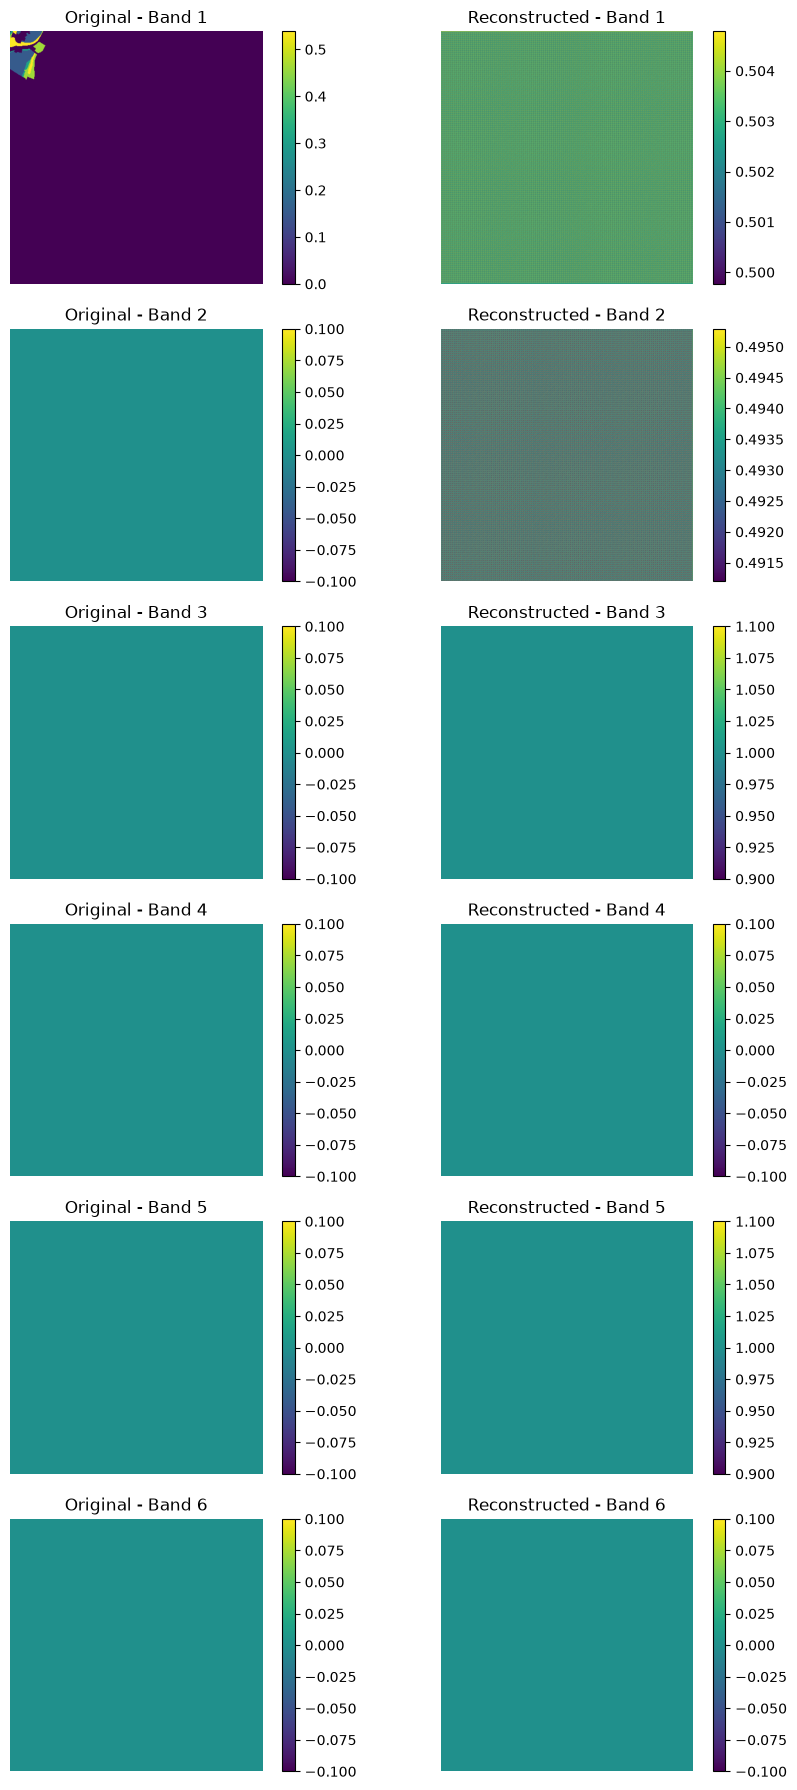

In [12]:
import matplotlib.pyplot as plt

# Convert tensors to NumPy arrays (detach from GPU/autograd graph)
input_np = dummy_512_patch.squeeze(0).cpu().detach().numpy()  # Shape: (35, 512, 512)
recon_np = recon.squeeze(0).cpu().detach().numpy()            # Shape: (35, 512, 512)

# Set how many channels you want to visualize
num_bands_to_plot = 6

fig, axes = plt.subplots(num_bands_to_plot, 2, figsize=(10, 3 * num_bands_to_plot))

for i in range(num_bands_to_plot):
    # Original Band
    ax_orig = axes[i, 0] if num_bands_to_plot > 1 else axes[0]
    im_orig = ax_orig.imshow(input_np[i], cmap='viridis')
    ax_orig.set_title(f"Original - Band {i + 1}")
    ax_orig.axis('off')
    fig.colorbar(im_orig, ax=ax_orig, fraction=0.046, pad=0.04)

    # Reconstructed Band
    ax_recon = axes[i, 1] if num_bands_to_plot > 1 else axes[1]
    im_recon = ax_recon.imshow(recon_np[i], cmap='viridis')
    ax_recon.set_title(f"Reconstructed - Band {i + 1}")
    ax_recon.axis('off')
    fig.colorbar(im_recon, ax=ax_recon, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

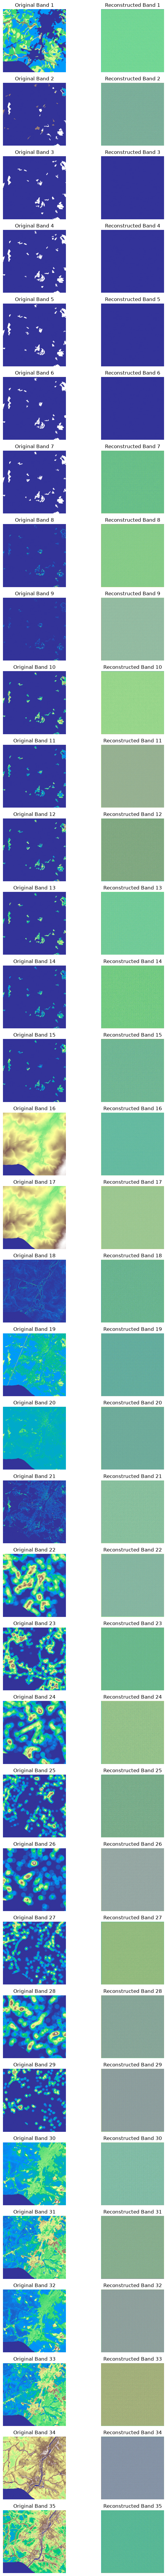

In [42]:
def plot_all_bands(input_tensor, recon_tensor, max_bands=35):
    input_np = input_tensor.squeeze(0).cpu().detach().numpy()
    recon_np = recon_tensor.squeeze(0).cpu().detach().numpy()
    
    num_bands = min(max_bands, input_np.shape[0])
    
    # 2 columns per band row (Original vs Reconstructed)
    fig, axes = plt.subplots(num_bands, 2, figsize=(8, 2.5 * num_bands))
    
    for i in range(num_bands):
        # Original
        im1 = axes[i, 0].imshow(input_np[i], cmap='terrain')
        axes[i, 0].set_title(f"Original Band {i+1}")
        axes[i, 0].axis('off')
        
        # Reconstruction
        im2 = axes[i, 1].imshow(recon_np[i], cmap='terrain')
        axes[i, 1].set_title(f"Reconstructed Band {i+1}")
        axes[i, 1].axis('off')
        
    plt.tight_layout()
    plt.show()

# Run for all 35 bands
plot_all_bands(dummy_512_patch, recon)

In [43]:
min_vals = recon.flatten(2).min(dim=-1).values
max_vals = recon.flatten(2).max(dim=-1).values

In [44]:
print(min_vals)

tensor([[0.5078, 0.4896, 0.0000, 0.0000, 1.0000, 0.0000, 0.5018, 0.5082, 0.4972,
         0.4950, 0.4993, 0.4880, 0.4923, 0.4941, 0.4938, 0.5007, 0.4884, 0.4998,
         0.4892, 0.4920, 0.5022, 0.5044, 0.5025, 0.4932, 0.5029, 0.5060, 0.5076,
         0.4889, 0.5045, 0.5068, 0.4999, 0.5071, 0.5039, 0.5059, 0.4890]],
       device='cuda:0')


In [45]:
print(max_vals)

tensor([[0.5105, 0.4927, 0.0000, 0.0000, 1.0000, 0.0000, 0.5054, 0.5119, 0.5019,
         0.4982, 0.5044, 0.4904, 0.4953, 0.4959, 0.4962, 0.5046, 0.4925, 0.5024,
         0.4932, 0.4972, 0.5046, 0.5081, 0.5061, 0.4956, 0.5049, 0.5103, 0.5109,
         0.4924, 0.5094, 0.5099, 0.5033, 0.5125, 0.5063, 0.5121, 0.4926]],
       device='cuda:0')
